In [1]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import hmp
import hmp.io
import hmp.utils
from helper_functions import HalfSine, EvidenceAccumulation, simulate_from_hmpfit

# Load Data from participants

In [12]:
# We need HMP predictions and real EEG data to compare.
# Workflow: HMP predictions -> predict EEG -> compare with real EEG

# ----------------------------------------------------------------------
# 0. Choose which participant to load / predict
# ----------------------------------------------------------------------
EEG_DATA_PATH = os.path.join('data')
ESTIMATION_PATH = os.path.join(EEG_DATA_PATH, 'estimation_files')

SFREQ = 250                          # use 100 for speed/RAM
TSTEP = 1000 / SFREQ                 # ms per sample, for plotting
N_PARTICIPANTS = 1                   # how many participants to use


# ----------------------------------------------------------------------
# 1. Load real EEG (all participants, then keep the first 5)
# ----------------------------------------------------------------------
subj_names = sorted([x.split('.')[0] for x in os.listdir(EEG_DATA_PATH) if x.endswith('.fif')])
subj_files = [os.path.join(EEG_DATA_PATH, x + '.fif') for x in subj_names]

preprocessing = dict(sfreq=SFREQ, pick_channels='eeg')
epoch_data, info = hmp.io.read_mne_epochs(subj_files,
                                          montage='biosemi64',
                                          preprocessing_kwargs=preprocessing)

# Remove baseline that is not modelled by HMP
epoch_data = epoch_data.sel(sample=range(epoch_data.sample.max().values))

# Select only the first 2 participants
epoch_data = epoch_data.isel(recording=range(N_PARTICIPANTS))


# ----------------------------------------------------------------------
# 2. Load HMP predictions
# ----------------------------------------------------------------------
# estimates = model outputs (event probabilities); model = the fitted model object
with open(os.path.join(ESTIMATION_PATH, 'estimates.pkl'), 'rb') as f:
    estimates = pickle.load(f)
with open(os.path.join(ESTIMATION_PATH, 'model.pkl'), 'rb') as f:
    model = pickle.load(f)

# Event topographies per trial and event (one scalp map per trial; mean=False)
weights = hmp.utils.event_channels(epoch_data, estimates, mean=False).squeeze()
# Most likely time of each event, with the RT as the last column
times = hmp.utils.event_times(estimates, add_rt=True)


Processing dataset 0
Reading C:\Users\cleli\PycharmProjects\EEG_Predictions\data\0_epo.fif ...
    Found the data of interest:
        t =    -199.22 ...    3000.00 ms
        0 CTF compensation matrices available
Adding metadata with 6 columns
1116 matching events found
No baseline correction applied
0 projection items activated
Epoch data will be decimated by 2 to achieve a sampling frequency of 256.0Hz
Processing dataset 10
Reading C:\Users\cleli\PycharmProjects\EEG_Predictions\data\10_epo.fif ...
    Found the data of interest:
        t =    -199.22 ...    3000.00 ms
        0 CTF compensation matrices available
Adding metadata with 6 columns
1116 matching events found
No baseline correction applied
0 projection items activated
Epoch data will be decimated by 2 to achieve a sampling frequency of 256.0Hz
Processing dataset 11
Reading C:\Users\cleli\PycharmProjects\EEG_Predictions\data\11_epo.fif ...
    Found the data of interest:
        t =    -199.22 ...    3000.00 ms
        0 

In [13]:
# ----------------------------------------------------------------------
# 3. Keep only the trials of the participants we selected
# ----------------------------------------------------------------------
recs = [str(r) for r in epoch_data.recording.values]
keep = np.where(np.isin(times.recording.values.astype(str), recs))[0]
# times: covers the whole model -> subset to the selected participants
keep_t = np.where(np.isin(times.recording.values.astype(str), recs))[0]
times = times.isel(trial=keep_t)


# Check that both refer to the same (recording, epoch) trials in the same order
t_ids = list(zip(times.recording.values.astype(str), times.epoch.values))
w_ids = list(zip(weights.recording.values.astype(str), weights.epoch.values))

# weights: already built from epoch_data, to have same order
weights = weights.isel(trial=[w_ids.index(t) for t in t_ids])

print("trials in times:", len(t_ids), "| trials in weights:", len(w_ids))
print("Same trials, same order:", t_ids == w_ids)

print("Participants:", recs, "| trials in model:", len(keep),
      "| epochs in data:", epoch_data.epoch.size * len(recs))
print("Channels in data:", epoch_data.channel.size, "| weights shape:", weights.shape)
print("NaNs in weights:", int(np.isnan(weights).sum()))


trials in times: 1100 | trials in weights: 1100
Same trials, same order: True
Participants: ['0'] | trials in model: 1100 | epochs in data: 1117
Channels in data: 32 | weights shape: (32, 1100, 4)
NaNs in weights: 0


In [14]:
# ----------------------------------------------------------------------
# 4. Keep in epoch_data only the trials used by HMP (rejected trials -> NaN)
# ----------------------------------------------------------------------
# (recording, epoch) pairs kept by HMP
kept = set(zip(times.recording.values.astype(str), times.epoch.values.astype(int)))

# True where the (recording, epoch) pair was kept by HMP
mask = xr.DataArray(
    np.array([[(str(r), int(e)) in kept for e in epoch_data.epoch.values]
              for r in epoch_data.recording.values]),
    dims=("recording", "epoch"),
    coords={"recording": epoch_data.recording, "epoch": epoch_data.epoch},
)

# Rejected trials (and empty grid cells) become NaN
epoch_data = epoch_data.where(mask)

# Check: number of non-empty trials should equal the number of trials in times
n_real = int(epoch_data["data"].notnull().any(["channel", "sample"]).sum())
print("trials in epoch_data:", n_real, "| trials in times:", times.trial.size)

trials in epoch_data: 1100 | trials in times: 1100


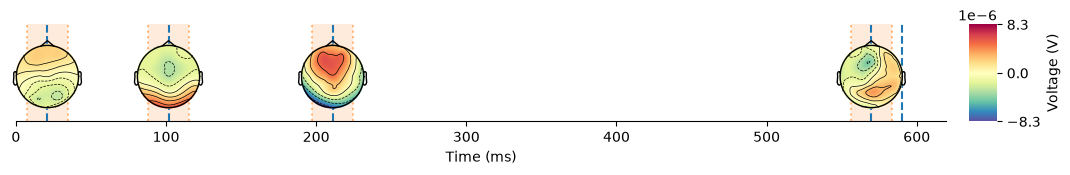

In [15]:
hmp.visu.plot_topo_timecourse(epoch_data, estimates, info, as_time=True, colorbar=True,)

# Simulate EEG

In [20]:
# An example using the default assumption of HMP regarding the pattern in the data
pattern_assumption = {0:HalfSine(SFREQ, width=50), 1:HalfSine(SFREQ, width=50), 
                      2:HalfSine(SFREQ, width=50), 3:HalfSine(SFREQ, width=50)}
# one pattern by event (here 4 events)
default_sim = simulate_from_hmpfit(epoch_data, weights, times, pattern_assumption)
print(default_sim)

<xarray.Dataset> Size: 110MB
Dimensions:     (recording: 1, epoch: 1117, channel: 32, sample: 768)
Coordinates:
  * recording   (recording) <U2 8B '0'
  * epoch       (epoch) int64 9kB 0 1 2 3 4 5 ... 1111 1112 1113 1114 1115 1116
    event_name  (recording, epoch) object 9kB 'stimulus/95' ... nan
    rt          (recording, epoch) float64 9kB 0.7197 0.4502 ... 0.627 nan
    condition   (recording, epoch) object 9kB 'accuracy' 'accuracy' ... nan
    side        (recording, epoch) object 9kB 'right' 'right' ... 'right' nan
    stimulus    (recording, epoch) object 9kB '95' '29' '42' ... '29' '12' nan
    response    (recording, epoch) object 9kB 'left' 'right' ... 'right' nan
    subject     (recording, epoch) <U2 9kB '0' '0' '0' '0' ... '0' '0' '0' '0'
  * channel     (channel) <U3 384B 'Fp1' 'AF3' 'F7' 'F3' ... 'Fp2' 'Fz' 'Cz'
  * sample      (sample) int64 6kB 0 1 2 3 4 5 6 ... 761 762 763 764 765 766 767
Data variables:
    data        (recording, epoch, channel, sample) float32 110

Text(0.5, 1.0, 'Default Half-Sine')

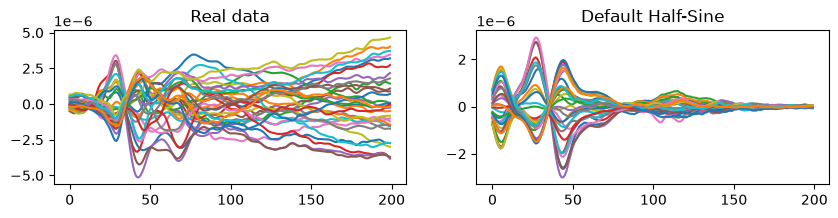

In [19]:
# Plotting the simulation
fig, ax = plt.subplots(1,2, figsize=(10, 2), sharey=False)
ax[0].plot(epoch_data.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T);
ax[0].set_title('Real data')
ax[1].plot(default_sim.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T);
ax[1].set_title('Default Half-Sine')

In [26]:
real = epoch_data.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T
print(epoch_data.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T)

<xarray.DataArray 'data' (sample: 200, channel: 32)> Size: 26kB
array([[ 4.3528559e-07,  5.6958453e-07,  3.4535742e-07, ...,
         5.3418972e-07,  1.1285898e-07, -1.8895804e-07],
       [ 4.5111139e-07,  5.8524228e-07,  4.2701257e-07, ...,
         5.4396924e-07,  1.2218393e-07, -1.9813471e-07],
       [ 4.8633456e-07,  6.0866915e-07,  5.3649831e-07, ...,
         5.9181218e-07,  1.3275542e-07, -2.1550846e-07],
       ...,
       [ 3.1580726e-06,  3.9244374e-06,  1.5336700e-06, ...,
         3.6868596e-06,  6.4063568e-07, -2.2131404e-07],
       [ 3.1623283e-06,  3.9483143e-06,  1.4725866e-06, ...,
         3.6945562e-06,  6.6882950e-07, -1.9717199e-07],
       [ 3.2011901e-06,  4.0249320e-06,  1.4338355e-06, ...,
         3.7199216e-06,  7.1919430e-07, -1.7373848e-07]],
      shape=(200, 32), dtype=float32)
Coordinates:
  * sample   (sample) int64 2kB 0 1 2 3 4 5 6 7 ... 193 194 195 196 197 198 199
  * channel  (channel) <U3 384B 'Fp1' 'AF3' 'F7' 'F3' ... 'AF4' 'Fp2' 'Fz' 'Cz'


In [27]:
predicted = default_sim.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T
print(default_sim.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T)

<xarray.DataArray 'data' (sample: 200, channel: 32)> Size: 26kB
array([[ 7.1903543e-07,  7.7154328e-07,  4.8566608e-07, ...,
         6.4569639e-07,  5.5178589e-07,  2.4878425e-08],
       [ 9.6426220e-07,  1.0368884e-06,  6.7247584e-07, ...,
         8.7600682e-07,  7.5602219e-07,  4.0057824e-08],
       [ 1.1946162e-06,  1.2884828e-06,  8.4026874e-07, ...,
         1.0933439e-06,  9.5816551e-07,  5.4936297e-08],
       ...,
       [-2.0709839e-08, -1.2727368e-08, -4.6497245e-08, ...,
        -1.6020715e-08, -5.1268707e-08,  1.0721429e-08],
       [-6.5569070e-09,  2.1836675e-09, -2.2703169e-08, ...,
         6.7934547e-09, -3.7244721e-08,  1.1041059e-08],
       [-1.6515639e-09,  5.0349587e-09, -8.1182785e-09, ...,
         1.7007379e-08, -4.8044107e-08,  1.4640789e-08]],
      shape=(200, 32), dtype=float32)
Coordinates:
  * sample   (sample) int64 2kB 0 1 2 3 4 5 6 7 ... 193 194 195 196 197 198 199
  * channel  (channel) <U3 384B 'Fp1' 'AF3' 'F7' 'F3' ... 'AF4' 'Fp2' 'Fz' 'Cz'


In [28]:
print(real - predicted)

<xarray.DataArray 'data' (sample: 200, channel: 32)> Size: 26kB
array([[-2.83749841e-07, -2.01958755e-07, -1.40308657e-07, ...,
        -1.11506665e-07, -4.38926918e-07, -2.13836472e-07],
       [-5.13150781e-07, -4.51646144e-07, -2.45463269e-07, ...,
        -3.32037587e-07, -6.33838226e-07, -2.38192541e-07],
       [-7.08281618e-07, -6.79813695e-07, -3.03770435e-07, ...,
        -5.01531758e-07, -8.25410098e-07, -2.70444758e-07],
       ...,
       [ 3.17878244e-06,  3.93716482e-06,  1.58016724e-06, ...,
         3.70288035e-06,  6.91904404e-07, -2.32035461e-07],
       [ 3.16888531e-06,  3.94613062e-06,  1.49528978e-06, ...,
         3.68776273e-06,  7.06074218e-07, -2.08213038e-07],
       [ 3.20284175e-06,  4.01989701e-06,  1.44195371e-06, ...,
         3.70291423e-06,  7.67238419e-07, -1.88379275e-07]],
      shape=(200, 32), dtype=float32)
Coordinates:
  * sample   (sample) int64 2kB 0 1 2 3 4 5 6 7 ... 193 194 195 196 197 198 199
  * channel  (channel) <U3 384B 'Fp1' 'AF3' 'F7'